In [10]:
import pandas as pd
import os
import pyarrow.parquet as pq
from PIL import Image
from io import BytesIO

train_df = pd.read_csv("metadata/train.csv")
val_df = pd.read_csv("metadata/val.csv")
test_df = pd.read_csv("metadata/test.csv")

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

display(train_df.head())

Train: (90256, 4)
Validation: (10923, 4)
Test: (10941, 4)


,shard,row_index,patient_id,pneumonia
0,train-00000-of-00006.parquet,0,1,0
1,train-00000-of-00006.parquet,1,1,0
2,train-00000-of-00006.parquet,2,1,0
3,train-00000-of-00006.parquet,3,2,0
4,train-00000-of-00006.parquet,4,3,0


## Loading and displaying an image

In [10]:
train_df.iloc[0]

shard         train-00000-of-00006.parquet
row_index                                0
patient_id                               1
pneumonia                                0
Name: 0, dtype: object

In [3]:
parquet_path = os.path.join(
    "data", "data", train_df.iloc[0]["shard"]
)

pf = pq.ParquetFile(parquet_path)

print(pf.schema)
print("Row groups:", pf.num_row_groups)
print("Rows:", pf.metadata.num_rows)

required group field_id=-1 schema {
  optional binary field_id=-1 patient_id (String);
  optional int32 field_id=-1 scan_id;
  optional group field_id=-1 image {
    optional binary field_id=-1 bytes;
    optional binary field_id=-1 path (String);
  }
  optional int32 field_id=-1 age;
  optional binary field_id=-1 sex (String);
  optional group field_id=-1 labels (List) {
    repeated group field_id=-1 list {
      optional int32 field_id=-1 element;
    }
  }
}

Row groups: 5
Rows: 18687


In [38]:
pathology_names = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Infiltration",
    "Mass",
    "Nodule",
    "Pneumonia",
    "Pneumothorax",
    "Consolidation",
    "Edema",
    "Emphysema",
    "Fibrosis",
    "Pleural Thickening",
    "Hernia",
]

row_index = int(train_df.iloc[0]["row_index"])
row_group = row_index // (pf.metadata.num_rows // pf.num_row_groups)

# Find the row group containing this row
group_start = sum(
    pf.metadata.row_group(g).num_rows
    for g in range(row_group)
)
offset = row_index - group_start

image_table = pf.read_row_group(
    row_group,
    columns=["image", "labels"]
)

image_data = image_table.slice(offset, 1)["image"][0].as_py()
labels = image_table.slice(offset, 1)["labels"][0].as_py()
image_bytes = image_data["bytes"]
print("Image bytes:", len(image_bytes))
print("Image path:", image_data["path"])


Image bytes: 24199
Image path: 1_0.png


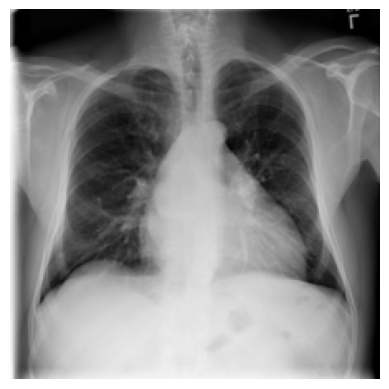

Image size: (224, 224)
Image mode: L


In [39]:
import matplotlib.pyplot as plt

image = Image.open(BytesIO(image_bytes))
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()

print("Image size:", image.size)
print("Image mode:", image.mode)

## Establishing an image loading pipeline

In [7]:
from torch.utils.data import Dataset
import torch

class ChestXrayDataset(Dataset):
    def __init__(self, dataframe, data_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.data_dir = data_dir
        self.transform = transform
        # Cache the currently open shard and row group
        self._cached_shard = None
        self._cached_pf = None
        self._cached_row_group = None
        self._cached_table = None
        self._cached_group_start = None
    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        metadata = self.dataframe.iloc[idx]
        shard = metadata["shard"]
        # Open a shard only when it changes
        if shard != self._cached_shard:
            parquet_path = os.path.join(self.data_dir, shard)
            self._cached_pf = pq.ParquetFile(parquet_path)
            self._cached_shard = shard
            self._cached_row_group = None
        pf = self._cached_pf

        row_index = int(metadata["row_index"])
        group_start = 0
        # Find the row group containing this row       
        for g in range(pf.num_row_groups):
            group_rows = pf.metadata.row_group(g).num_rows
        
            if row_index < group_start + group_rows:
                row_group = g
                offset = row_index - group_start
                break
        
            group_start += group_rows
        else:
            raise IndexError(f"Row index {row_index} is out of range")
        # Read a row group only if it isn't already cached
        if row_group != self._cached_row_group:
            self._cached_table = pf.read_row_group(
                row_group, columns=["image", "labels"]
            )
            self._cached_row_group = row_group
            self._cached_group_start = group_start
        
        image_data = self._cached_table.slice(offset, 1)["image"][0].as_py()
        labels = self._cached_table.slice(offset, 1)["labels"][0].as_py()
        
        image = Image.open(BytesIO(image_data["bytes"])).convert("RGB")
        target = torch.zeros(14, dtype=torch.float32)

        for label_id in labels:
            if label_id != 0:
                target[label_id - 1] = 1.0
        
        if self.transform:
            image = self.transform(image)
        return image, target

In [8]:
from torch.utils.data import DataLoader
from torchvision import transforms
transform = transforms.Compose([
    transforms.ToTensor(),
])

train_dataset = ChestXrayDataset(train_df, data_dir='data/data/', transform=transform)
train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0,
)

In [18]:
images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Labels:", labels)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

Images: torch.Size([8, 3, 224, 224])
Labels: torch.Size([8, 14])
Labels: tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 1., 1., 0., 0., 0., 0., 0., 1., 0., 0., 0.],
        [0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 1., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.]])
Image dtype: torch.float32
Label dtype: torch.float32


## ResNet-18

In [12]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
train_dataset = ChestXrayDataset(train_df, data_dir='data/data/', transform=transform)
train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0,
)

In [13]:
images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Labels:", labels)
print("Image dtype:", images.dtype)

Images: torch.Size([8, 3, 224, 224])
Labels: torch.Size([8, 14])
Labels: tensor([[0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])
Image dtype: torch.float32


In [14]:
import torch
from torchvision.models import resnet18, ResNet18_Weights

weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)

In [15]:
model.fc = torch.nn.Linear(model.fc.in_features, 14)

In [16]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
images = images.to(device)
labels = labels.to(device)
with torch.no_grad():
    outputs = model(images)
    
print("Device:", device)
print("Images:", images.shape)
print("Labels:", labels.shape)
print("Model output:", outputs.shape)

Device: cuda
Images: torch.Size([8, 3, 224, 224])
Labels: torch.Size([8, 14])
Model output: torch.Size([8, 14])


In [17]:
criterion = torch.nn.BCEWithLogitsLoss()
loss = criterion(outputs, labels)
print("Initial loss:", loss.item())


Initial loss: 0.6946346163749695


In [29]:
import time

def evaluate_loss(loader, model):
    model.eval()
    total_loss = 0.0
    total_samples = 0
    start_time = time.time()

    with torch.no_grad():
        for batch_idx, (images, labels) in enumerate(loader):
            images = images.to(device)
            labels = labels.to(device)

            scores = model(images)
            loss = criterion(scores, labels)

            batch_size = images.size(0)
            total_loss += loss.item() * batch_size
            total_samples += batch_size

            if (batch_idx + 1) % 100 == 0:
                print(
                    f"Batch {batch_idx + 1}/{len(loader)}, "
                    f"elapsed: {(time.time() - start_time) / 60:.1f} min"
                )

    return total_loss / total_samples
    
def train(model, optimizer, epochs=1, print_every=100):
    model = model.to(device)

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        total_samples = 0

        for step, (images, labels) in enumerate(train_loader):
            images = images.to(device)
            labels = labels.to(device, dtype=torch.float32)

            scores = model(images)
            loss = criterion(scores, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            batch_size = images.size(0)
            total_loss += loss.item() * batch_size
            total_samples += batch_size

            # Print progress periodically
            if (step + 1) % print_every == 0:
                avg_loss = total_loss / total_samples
                print(
                    f"Epoch {epoch + 1}/{epochs} | "
                    f"Batch {step + 1}/{len(train_loader)} | "
                    f"Average loss: {avg_loss:.4f}"
                )
        train_loss = total_loss / total_samples
        val_loss = evaluate_loss(val_loader, model)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Validation loss: {val_loss:.4f}"
        )


In [20]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [25]:
val_dataset = ChestXrayDataset(val_df, data_dir='data/data/', transform=transform)
val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0,
)

In [24]:
train(model, optimizer, epochs=1)

Epoch 1/1 | Batch 100/11282 | Average loss: 0.1664
Epoch 1/1 | Batch 200/11282 | Average loss: 0.1672
Epoch 1/1 | Batch 300/11282 | Average loss: 0.1629
Epoch 1/1 | Batch 400/11282 | Average loss: 0.1623
Epoch 1/1 | Batch 500/11282 | Average loss: 0.1632
Epoch 1/1 | Batch 600/11282 | Average loss: 0.1614
Epoch 1/1 | Batch 700/11282 | Average loss: 0.1623
Epoch 1/1 | Batch 800/11282 | Average loss: 0.1621
Epoch 1/1 | Batch 900/11282 | Average loss: 0.1617
Epoch 1/1 | Batch 1000/11282 | Average loss: 0.1605
Epoch 1/1 | Batch 1100/11282 | Average loss: 0.1611
Epoch 1/1 | Batch 1200/11282 | Average loss: 0.1618
Epoch 1/1 | Batch 1300/11282 | Average loss: 0.1627
Epoch 1/1 | Batch 1400/11282 | Average loss: 0.1620
Epoch 1/1 | Batch 1500/11282 | Average loss: 0.1619
Epoch 1/1 | Batch 1600/11282 | Average loss: 0.1618
Epoch 1/1 | Batch 1700/11282 | Average loss: 0.1613
Epoch 1/1 | Batch 1800/11282 | Average loss: 0.1616
Epoch 1/1 | Batch 1900/11282 | Average loss: 0.1620
Epoch 1/1 | Batch 200

NameError: name 'val_loader' is not defined

In [30]:
val_loss = evaluate_loss(val_loader, model)
val_loss

Batch 100/1366, elapsed: 1.2 min
Batch 200/1366, elapsed: 2.4 min
Batch 300/1366, elapsed: 3.6 min
Batch 400/1366, elapsed: 4.7 min
Batch 500/1366, elapsed: 5.9 min
Batch 600/1366, elapsed: 7.0 min
Batch 700/1366, elapsed: 8.1 min
Batch 800/1366, elapsed: 9.4 min
Batch 900/1366, elapsed: 10.5 min
Batch 1000/1366, elapsed: 11.7 min
Batch 1100/1366, elapsed: 12.8 min
Batch 1200/1366, elapsed: 14.0 min
Batch 1300/1366, elapsed: 15.2 min


0.15734707701285877

In [28]:
from pathlib import Path
checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(exist_ok=True)

torch.save(
    {
        "epoch": 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
    },
    checkpoint_dir / "resnet18_epoch1.pth",
)

print("Checkpoint saved.")

Checkpoint saved.
